# Import and process data

Decided to filter out EANs where yearly consumption is below 365 kWh

In [19]:
import pandas as pd

df = pd.read_csv("data/Apico-2025-3-1-2026-3-1 2.csv")
df.head()

,time,Import T1 kWh,Import T2 kWh,Export T1 kWh,Export T2 kWh,L1 max W,L2 max W,L3 max W
0,2025-03-01 00:00,3694.718,7766.927,5164.87,1720.366,-33,-23,72
1,2025-03-01 00:15,3694.718,7766.928,5164.87,1720.368,-1,19,60
2,2025-03-01 00:30,3694.718,7766.931,5164.87,1720.368,-18,7,42
3,2025-03-01 00:45,3694.718,7766.938,5164.87,1720.368,-27,4,38
4,2025-03-01 01:00,3694.718,7766.940,5164.87,1720.368,-8,20,38


# Plot average, min and max daily profiles

In [20]:
import matplotlib.pyplot as plt

def plot_daily_pattern(index, data=df):
    """
    Plot the average daily pattern with min/max envelopes for a given EAN.
    
    Parameters:
    ean (str): The EAN value to filter
    data (DataFrame): The dataframe to use (default: df)
    """
    ean = unique_eans[index]
    
    # Filter data for the specific EAN
    ean_data = data[data['ean_anon'] == ean].copy()
    
    # Convert measuredatetime to datetime
    ean_data['measuredatetime'] = pd.to_datetime(ean_data['measuredatetime'])
    
    # Extract time of day (hour and minute)
    ean_data['time_of_day'] = ean_data['measuredatetime'].dt.time
    
    # sort by datetime, compute first difference of measure_cons and drop the first NaN row
    ean_data.sort_values('measuredatetime', inplace=True)
    ean_data['power_cons'] = ean_data['measure_cons'].diff()
    ean_data = ean_data.iloc[1:].copy()
    
    # Group by time of day and calculate mean, min, max of measure_cons
    daily_pattern = ean_data.groupby('time_of_day')['power_cons'].agg(['mean', 'min', 'max'])
    
    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(daily_pattern)), daily_pattern['mean'], label='Average', linewidth=2)
    plt.fill_between(range(len(daily_pattern)), daily_pattern['min'], daily_pattern['max'], 
                     alpha=0.3, label='Min/Max Envelope')
    
    plt.xlabel('Time of Day')
    plt.ylabel('Consumption (power_cons) [kW]')
    plt.title(f'Daily Pattern for EAN index: {index}')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return ean_data


In [31]:
import matplotlib.pyplot as plt

def plot_daily_pattern(ean_data):
    """
    Plot the average daily pattern with min/max envelopes for a given EAN.
    
    Parameters:
    ean (str): The EAN value to filter
    data (DataFrame): The dataframe to use (default: df)
    """
    
    # Convert time to datetime
    ean_data['time'] = pd.to_datetime(ean_data['time'])
    
    # Extract time of day (hour and minute)
    ean_data['time_of_day'] = ean_data['time'].dt.time
    
    # sort by datetime, compute first difference of measure_cons and drop the first NaN row
    ean_data.sort_values('time', inplace=True)
    
    ean_data["total_consumption"] = ean_data["Import T1 kWh"] + ean_data["Import T2 kWh"]
    ean_data["total_injection"] = ean_data["Export T1 kWh"] + ean_data["Export T2 kWh"]

    ean_data['power_in'] = ean_data['total_consumption'].diff()*4
    ean_data['power_out'] = ean_data['total_injection'].diff()*4

    # Get rid of the first line after diff
    ean_data = ean_data.iloc[1:].copy()
    
    # Group by time of day and calculate mean, min, max of measure_cons
    daily_pattern_cons = ean_data.groupby('time_of_day')['power_in'].agg(['mean', 'min', 'max'])
    daily_pattern_inj = ean_data.groupby('time_of_day')['power_out'].agg(['mean', 'min', 'max'])
    
    # Plot
    plt.figure(figsize=(12, 6))
    plt.plot(range(len(daily_pattern_cons)), daily_pattern_cons['mean'], label='Average', linewidth=2)
    plt.fill_between(range(len(daily_pattern_cons)), daily_pattern_cons['min'], daily_pattern_cons['max'], 
                     alpha=0.3, label='Min/Max Envelope')
    plt.plot(range(len(daily_pattern_inj)), -daily_pattern_inj['mean'], label='Average', linewidth=2)
    plt.fill_between(range(len(daily_pattern_inj)), -daily_pattern_inj['min'], -daily_pattern_inj['max'], 
                     alpha=0.3, label='Min/Max Envelope')
    plt.xlabel('Time of Day')
    plt.ylabel('Consumption (power_cons) [kW]')
    plt.title(f'Daily Pattern')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return ean_data


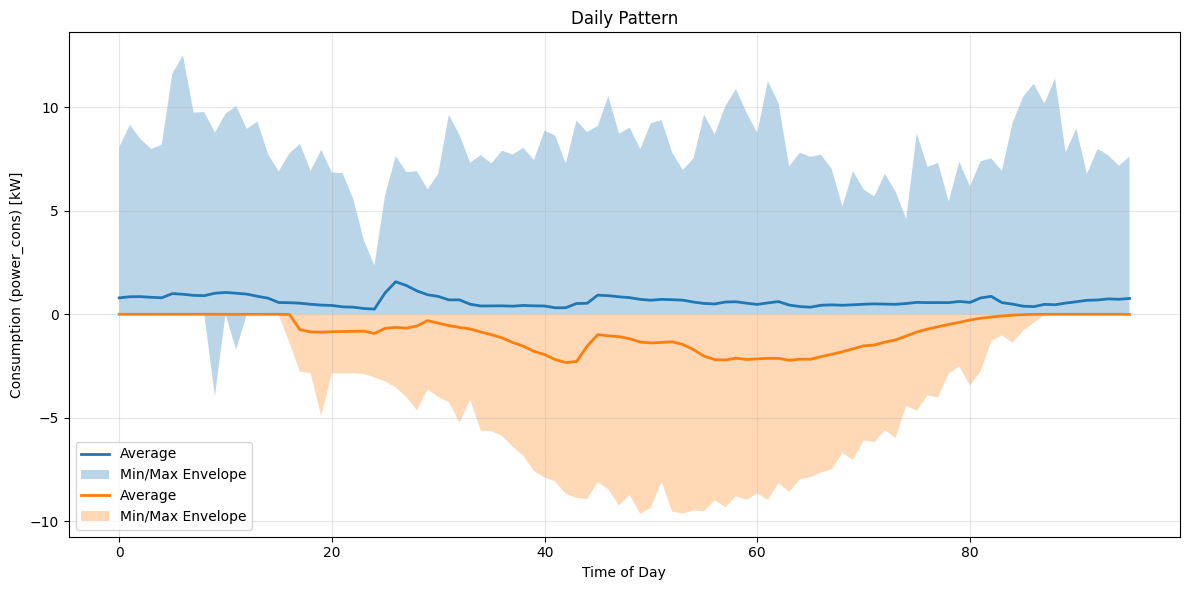

In [32]:
ean_data = plot_daily_pattern(df)

In [23]:
ean_data.head()

,time,Import T1 kWh,Import T2 kWh,Export T1 kWh,Export T2 kWh,L1 max W,L2 max W,L3 max W,time_of_day,total_consumption,total_injection,power_in,power_out
1,2025-03-01 00:15:00,3694.718,7766.928,5164.87,1720.368,-1,19,60,00:15:00,11461.646,6885.238,0.004,0.008
2,2025-03-01 00:30:00,3694.718,7766.931,5164.87,1720.368,-18,7,42,00:30:00,11461.649,6885.238,0.012,0.000
3,2025-03-01 00:45:00,3694.718,7766.938,5164.87,1720.368,-27,4,38,00:45:00,11461.656,6885.238,0.028,0.000
4,2025-03-01 01:00:00,3694.718,7766.940,5164.87,1720.368,-8,20,38,01:00:00,11461.658,6885.238,0.008,0.000
5,2025-03-01 01:15:00,3694.718,7766.940,5164.87,1720.369,-9,18,81,01:15:00,11461.658,6885.239,0.000,0.004


# Plot yearly consumptions 

In [26]:
# Extract year
ean_data['year'] = ean_data['time'].dt.year
yearly_cons = ean_data.groupby(['year'])['total_consumption'].max() - ean_data.groupby(['year'])['total_consumption'].min()
yearly_cons = yearly_cons.reset_index()
yearly_inj = ean_data.groupby(['year'])['total_injection'].max() - ean_data.groupby(['year'])['total_injection'].min()
yearly_inj = yearly_inj.reset_index()



In [25]:
yearly_cons

,year,total_consumption
0,2025,3226.178
1,2026,2346.359


In [27]:
yearly_inj

,year,total_injection
0,2025,7578.225
1,2026,156.662
